# Convolutional Neural Networks

## Project: Write an Algorithm for Landmark Classification


### Transfer learning

In the previous notebook we have trained our own CNN and we got a certain performance. Let's see how hard it is to match that performance with transfer learning.

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 0: Setting up

The following cells make sure that your environment is setup correctly and check that your GPU is available and ready to go. You have to execute them every time you restart your notebook.

In [1]:
# Install requirements
# !pip install -r requirements.txt | grep -v "already satisfied"

In [1]:
# Automatically reload modules before executing user code
%load_ext autoreload 
%autoreload 2 

In [2]:
from src.helpers import setup_env

# If running locally, this will download dataset (make sure you have at 
# least 2 Gb of space on your hard drive)
setup_env()

GPU available
Dataset already downloaded. If you need to re-download, please delete the directory landmark_images
Reusing cached mean and std


/workspace/code/project/src/helpers.py:94: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  d = torch.load(cache_file)


---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 1: Create transfer learning architecture

Open the file `src/transfer.py` and complete the `get_model_transfer_learning` function. When you are done, execute this test:

In [10]:
!pytest -vv src/transfer.py

============================= test session starts ==============================
platform linux -- Python 3.12.12, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3.12
cachedir: .pytest_cache
rootdir: /workspace/code/project
configfile: pytest.ini
plugins: anyio-4.12.1
collected 2 items                                                              

src/transfer.py::test_get_model_transfer_learning PASSED                 [ 50%]
src/transfer.py::test_only_new_head_is_trainable PASSED                  [100%]

=============================== warnings summary ===============================
src/transfer.py::test_get_model_transfer_learning
  /workspace/code/project/src/helpers.py:94: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untru

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 2: Train, validation and test

Let's train our transfer learning model! Let's start defining the hyperparameters:

In [4]:
import os

batch_size = 64        # small enough for most GPUs; the frozen backbone keeps memory low
valid_size = 0.2       # fraction of the training data to reserve for validation
num_epochs = 40        # maximum epochs; early stopping in optimize() usually stops sooner
num_classes = 50       # number of classes. Do not change this
learning_rate = 0.001  # only the new linear head is trained, so a moderate rate converges quickly
opt = 'adamw'          # Adam with decoupled weight decay
weight_decay = 0.01    # mild regularization of the head to limit overfitting
model_name = 'resnet50'  # ImageNet-pretrained backbone (torchvision "DEFAULT" weights)
# Overlap decoding/augmentation with GPU work, with a bounded shared-memory queue.
# Set num_workers=0 for the diagnostic single-process fallback.
num_workers = min(2, os.cpu_count() or 1)
prefetch_factor = 1
mp_context = "spawn"

In [6]:
import gc
import torch
from src.data import get_data_loaders
from src.optimization import get_optimizer, get_loss
from src.train import optimize
from src.transfer import get_model_transfer_learning

# Fix the seed so the train/validation split and head initialization are reproducible
torch.manual_seed(42)

model_transfer = get_model_transfer_learning(model_name, n_classes=num_classes)

# train the model
data_loaders = get_data_loaders(
    batch_size=batch_size, valid_size=valid_size, num_workers=num_workers,
    multiprocessing_context=mp_context,
    prefetch_factor=prefetch_factor,
)
optimizer = get_optimizer(
    model_transfer,
    learning_rate=learning_rate,
    optimizer=opt,
    weight_decay=weight_decay,
)
loss = get_loss()

optimize(
    data_loaders,
    model_transfer,
    optimizer,
    loss,
    n_epochs=num_epochs,
    save_path="checkpoints/model_transfer.pt",
    interactive_tracking=False,
    history_path="checkpoints/model_transfer_history.json",
)

# Keep only what later steps need, then shut down the persistent train/valid
# worker processes and release cached GPU memory before testing and export
class_names = data_loaders["train"].dataset.classes
test_dataset = data_loaders["test"].dataset
del data_loaders, optimizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])


Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.83it/s]


Epoch: 1 	Training Loss: 2.919842 	Validation Loss: 2.079363 	Validation Accuracy: 66.50%
New minimum validation loss: 2.079363. Saving model ...


Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.86it/s]


Epoch: 2 	Training Loss: 1.664448 	Validation Loss: 1.437488 	Validation Accuracy: 74.10%
New minimum validation loss: 1.437488. Saving model ...


Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.83it/s]


... (71 outputs left out)

Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.94it/s]


Epoch: 39 	Training Loss: 0.090708 	Validation Loss: 0.726099 	Validation Accuracy: 82.60%
New minimum validation loss: 0.726099. Saving model ...


Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.95it/s]


Epoch: 40 	Training Loss: 0.089980 	Validation Loss: 0.734792 	Validation Accuracy: 82.10%


In [7]:
import json

# Exact per-epoch metrics saved by optimize(). The live plot above clears printed
# output, and this file is also available after a disconnect or kernel restart.
with open("checkpoints/model_transfer_history.json") as f:
    history = json.load(f)

print(f"{'Epoch':>5} {'Train loss':>11} {'Valid loss':>11} {'Valid acc':>10} {'LR':>9}  Saved")
for row in history:
    print(
        f"{row['epoch']:>5} {row['train_loss']:>11.4f} {row['valid_loss']:>11.4f} "
        f"{row['valid_accuracy']:>9.2f}% {row['lr']:>9.1e}  {'*' if row['saved'] else ''}"
    )

# The checkpoint that was kept (and is used for testing) is the last saved epoch
best = [row for row in history if row["saved"]][-1]
peak = max(history, key=lambda row: row["valid_accuracy"])
print(
    f"\nEpochs run: {len(history)}"
    f"\nFinal train loss: {history[-1]['train_loss']:.4f}"
    f"\nSaved checkpoint: epoch {best['epoch']} (valid loss {best['valid_loss']:.4f}, "
    f"valid acc {best['valid_accuracy']:.2f}%, train loss {best['train_loss']:.4f})"
    f"\nPeak valid acc: {peak['valid_accuracy']:.2f}% (epoch {peak['epoch']})"
)

Epoch  Train loss  Valid loss  Valid acc        LR  Saved
    1      2.9198      2.0794     66.50%   1.0e-03  *
    2      1.6644      1.4375     74.10%   1.0e-03  *
    3      1.1829      1.1862     75.40%   1.0e-03  *
    4      0.9193      1.0467     77.30%   1.0e-03  *
    5      0.7659      0.9620     78.70%   1.0e-03  *
    6      0.6651      0.9178     79.50%   1.0e-03  *
    7      0.5772      0.8666     80.50%   1.0e-03  *
    8      0.5217      0.8450     80.70%   1.0e-03  *
    9      0.4636      0.8281     80.50%   1.0e-03  *
   10      0.4138      0.8033     81.10%   1.0e-03  *
   11      0.3798      0.7929     81.10%   1.0e-03  *
   12      0.3512      0.7774     81.50%   1.0e-03  *
   13      0.3163      0.7728     80.40%   1.0e-03  *
   14      0.3005      0.7650     81.20%   1.0e-03  *
   15      0.2796      0.7554     81.80%   1.0e-03  *
   16      0.2595      0.7455     81.30%   1.0e-03  *
   17      0.2374      0.7473     81.80%   1.0e-03  
   18      0.2235      0.

<img src="static_images/icons/noun-question-mark-869751.png" alt="?" style="width:25px"/> __Question:__ Outline the steps you took to get to your final CNN architecture and your reasoning at each step.  Describe why you think the architecture is suitable for the current problem.

<img src="static_images/icons/noun-answer-3361020.png" alt=">" style="width:25px"/>  __Answer:__

1. **Start from a strong pretrained backbone.** The dataset has only about 5,000 training images across 50 classes, which is too few to learn general visual features from scratch (Part 1 reached about 60%). A network pretrained on ImageNet's 1.2M images already detects edges, textures, shapes and object parts. These features carry over well to photos of buildings, natural scenery and monuments.
2. **Choose ResNet-50.** Residual connections support deep feature extraction. ResNet-50 provides 2048-dimensional pooled features, compared with ResNet-18's 512. In the recorded experiments, ResNet-50 has the lowest saved validation loss (0.7261) and highest validation accuracy at the saved checkpoint (82.60%), compared with ResNet-18 (1.0995, 73.80%) and ResNet-152 (0.7721, 81.90%). The deeper ResNet-152 did not improve this workflow. The ResNet-18 run also uses different optimizer settings and batch size, so this is a comparison of training configurations, not a controlled architecture-only comparison.
3. **Freeze the backbone and replace only the head.** All pretrained parameters are frozen, and the final `fc` layer is replaced with a new `Linear(2048, 50)` layer (102,450 trainable parameters). This avoids backpropagation through the backbone and limits the number of parameters learned from the small dataset. BatchNorm running statistics still update during training because the shared training loop calls `model.train()`; frozen parameters do not freeze these buffers.
4. **Training strategy.** I use the same augmented, normalized data pipeline as in Part 1 and AdamW with mild weight decay on the head. Training uses mixed precision and gradient clipping. A `ReduceLROnPlateau` scheduler lowers the learning rate when the validation loss stalls. The best validation-loss checkpoint is kept, and early stopping ends training once validation stops improving. Hyperparameters were chosen on the validation set only; the test set is evaluated once at the end.

This combination is suitable because landmark recognition relies on the same mid- and high-level visual cues (architecture, textures, skylines, natural formations) that ImageNet features already encode. A linear classifier on top of those features can therefore separate the 50 landmark classes with far less data than a network trained from scratch.

Now play with the hyperparameters and see which performance you can get on the validation set. You should get at least 60% for a passing grade, but a good model choice and a good training strategy could get you up to 80% or so. Let's see how close you can get!

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 3: Test the Model

Try out your model on the test dataset of landmark images. Use the code cell below to calculate and print the test loss and accuracy.  Ensure that your test accuracy is greater than 60% and matches more or less what you got on the validation set (otherwise you're overfitting!)

In [8]:
import torch
from torch.utils.data import DataLoader
from src.data import get_data_loaders
from src.optimization import get_loss
from src.train import one_epoch_test
from src.transfer import get_model_transfer_learning

# Restart-safe: after a disconnect/kernel restart, re-run the hyperparameter
# cell and continue from here using the saved checkpoint (no retraining needed)
if "test_dataset" not in globals():
    _loaders = get_data_loaders(
        batch_size=batch_size, valid_size=valid_size, num_workers=num_workers,
        multiprocessing_context=mp_context,
        prefetch_factor=prefetch_factor,
    )
    class_names = _loaders["train"].dataset.classes
    test_dataset = _loaders["test"].dataset
    del _loaders
loss = get_loss()

# Non-persistent loader: its worker processes exit as soon as testing finishes
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=torch.cuda.is_available(),
    multiprocessing_context=mp_context if num_workers > 0 else None,
    prefetch_factor=prefetch_factor if num_workers > 0 else None,
)

# pretrained=False: the trained weights are loaded from the checkpoint right after
model_transfer = get_model_transfer_learning(model_name, n_classes=num_classes, pretrained=False)
# Load saved weights
model_transfer.load_state_dict(
    torch.load('checkpoints/model_transfer.pt', map_location='cpu', weights_only=True)
)

one_epoch_test(test_loader, model_transfer, loss)

Testing: 100%|██████████████████████████████████| 20/20 [00:16<00:00,  1.20it/s]

Test Loss: 0.665208


Test Accuracy: 82% (1031/1250)


0.6652082899093628

---
## <img src="static_images/icons/noun-advance-2109145.png" alt=">" style="width:50px"/> Step 4: Export using torchscript

Now, just like we did with our original model, we export the best fit model using torchscript so that it can be used in our application:

In [9]:
# Disable autoreload so TorchScript does not see redefined classes
%autoreload 0

from src.predictor import Predictor
from src.helpers import compute_mean_and_std

# class_names was saved from the train dataset in the previous steps

# Then let's move the model_transfer to the CPU
# (we don't need GPU for inference)
model_transfer = model_transfer.cpu()
# Let's make sure we use the right weights by loading the
# best weights we have found during training
# NOTE: remember to use map_location='cpu' so the weights
# are loaded on the CPU (and not the GPU)
model_transfer.load_state_dict(
    torch.load("checkpoints/model_transfer.pt", map_location="cpu", weights_only=True)
)

# Let's wrap our model using the predictor class
mean, std = compute_mean_and_std()
predictor = Predictor(model_transfer, class_names, mean, std).cpu()

# Export using torch.jit.script
scripted_predictor = torch.jit.script(predictor)
scripted_predictor.save("checkpoints/transfer_exported.pt")

Reusing cached mean and std


100%|███████████████████████████████████████| 1250/1250 [00:22<00:00, 55.89it/s]


Accuracy: 0.8224


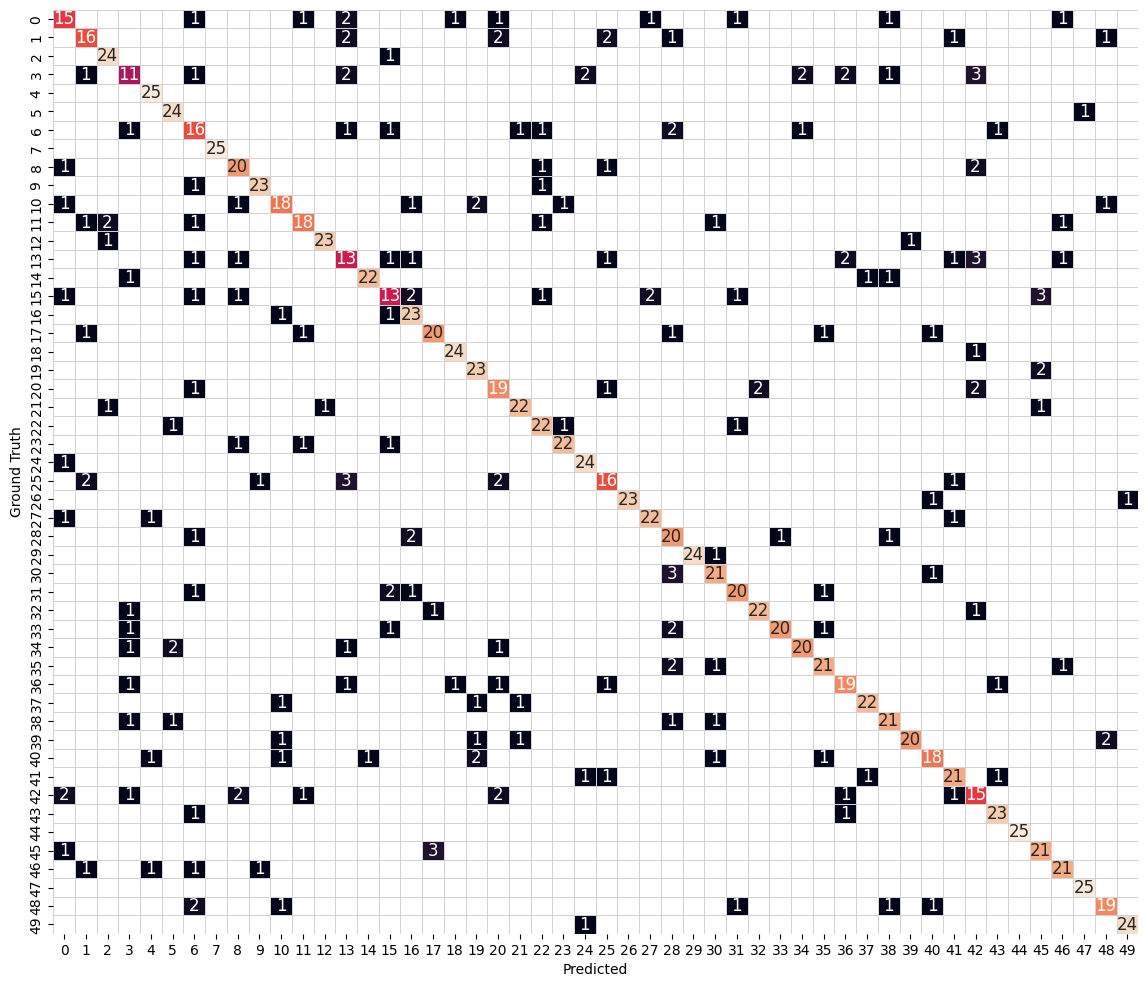

In [10]:
import torch
from torch.utils.data import DataLoader
from src.predictor import predictor_test
from src.helpers import plot_confusion_matrix

# The exported model resizes raw images itself, and raw test images have
# different sizes, so they are fed one at a time. predictor_test only reads
# batch_size and num_workers from this loader, so no new datasets are built.
test_loader_single = DataLoader(
    test_dataset, batch_size=1, num_workers=num_workers,
    multiprocessing_context=mp_context if num_workers > 0 else None,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
model_reloaded = torch.jit.load("checkpoints/transfer_exported.pt", map_location=device)

pred, truth = predictor_test(test_loader_single, model_reloaded)

plot_confusion_matrix(pred, truth)

---
## (Stand out) Backbone comparison: ResNet-18 and ResNet-152

These cells train the two alternative backbones from the experiment log. Each uses **exactly the same train/validation split** as the final ResNet-50 run, so their validation metrics can be compared directly.

- Each run writes its own checkpoint and history (`checkpoints/exp_<backbone>.pt`, `checkpoints/exp_<backbone>_history.json`). The final ResNet-50 checkpoint and `transfer_exported.pt` are **not** touched.
- Only validation metrics are reported; the test set stays reserved for the final model.
- **Recommended:** restart the kernel first, then run Step 0, the hyperparameter cell and the cells below. The final model is already saved, so nothing is lost, and each run starts with a small, clean kernel. The helper cell also frees the exported models from earlier steps if you continue without restarting.
- Each run cell can be run on its own, so after a disconnect re-run Step 0, the hyperparameter cell and the helper cell, then continue with the unfinished run. This restarts that run; it does not resume optimizer state.
- **Bounded parallel loading:** two spawned workers prepare images while the GPU computes, with one prefetched batch per worker. At batch size 128, queued float32 image tensors are about 147 MiB per loader (train and validation workers persist); this is an estimate, not a hard memory cap. Set `num_workers=0` for single-process diagnostics. Live plots remain disabled; epoch metrics are printed and saved to JSON. Batch sizes and model training settings are unchanged.
- Resource reports are appended to `checkpoints/part2_resources.jsonl`. Container memory limits/events matter even when `free -h` shows abundant host RAM. Native crash traces go to `checkpoints/part2_faults.log`; SIGKILL/OOM kills cannot produce a Python traceback. After a crash, restart and run the helper cell again to record the container's current OOM counters.

In [12]:
import gc
import json
import time
import torch
from src.data import get_data_loaders
from src.optimization import get_optimizer, get_loss
from src.train import optimize
from src.transfer import get_model_transfer_learning

import faulthandler
import os
from pathlib import Path

Path("checkpoints").mkdir(exist_ok=True)
if "_fault_log" not in globals():
    _fault_log = open("checkpoints/part2_faults.log", "a", buffering=1)
faulthandler.enable(file=_fault_log, all_threads=True)


def report_resources(stage):
    report = {"stage": stage, "time": time.time(), "pid": os.getpid()}
    paths = (
        "/proc/self/cgroup", "/proc/self/status",
        "/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current",
        "/sys/fs/cgroup/memory.peak", "/sys/fs/cgroup/memory.events",
        "/sys/fs/cgroup/memory/memory.limit_in_bytes",
        "/sys/fs/cgroup/memory/memory.usage_in_bytes",
        "/sys/fs/cgroup/memory/memory.failcnt",
    )
    for name in paths:
        path = Path(name)
        report[name] = path.read_text().strip() if path.is_file() else "unavailable"
    if Path("/dev/shm").is_dir():
        shm = os.statvfs("/dev/shm")
        report["shm_available_bytes"] = shm.f_bavail * shm.f_frsize
    if torch.cuda.is_available():
        report["cuda_allocated_bytes"] = torch.cuda.memory_allocated()
        report["cuda_peak_allocated_bytes"] = torch.cuda.max_memory_allocated()
    with open("checkpoints/part2_resources.jsonl", "a") as f:
        f.write(json.dumps(report) + "\n")
    print(json.dumps(report, indent=2), flush=True)

# Release large objects left over from testing/export (GPU TorchScript model,
# predictor wrappers, gallery features) so the comparison runs start lean
for _name in ("model_reloaded", "scripted_predictor", "predictor", "test_loader",
              "test_loader_single", "feature_extractor", "gallery_features"):
    globals().pop(_name, None)
if "model_transfer" in globals():
    model_transfer.cpu()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
report_resources("comparison setup")


def _same_split_loaders(batch_size):
    """Rebuild the loaders with the exact train/valid split of the final run.

    In the training cell the split comes from torch.randperm right after
    torch.manual_seed(42) and the ResNet-50 construction, which consumes the global
    RNG. Building the same (untrained, CPU-only) ResNet-50 again reproduces that RNG
    state, so every backbone is validated on identical images.
    """
    torch.manual_seed(42)
    get_model_transfer_learning("resnet50", n_classes=num_classes, pretrained=False)
    return get_data_loaders(
        batch_size=batch_size, valid_size=valid_size, num_workers=num_workers,
        multiprocessing_context=mp_context,
        prefetch_factor=prefetch_factor,
    )


def summarize_history(history_path):
    with open(history_path) as f:
        history = json.load(f)
    saved = [row for row in history if row["saved"]][-1]
    peak = max(history, key=lambda row: row["valid_accuracy"])
    return {
        "epochs": len(history),
        "final_train_loss": history[-1]["train_loss"],
        "saved_epoch": saved["epoch"],
        "best_valid_loss": saved["valid_loss"],
        "valid_acc_at_saved": saved["valid_accuracy"],
        "peak_valid_acc": peak["valid_accuracy"],
        "peak_epoch": peak["epoch"],
        "final_lr": history[-1]["lr"],
    }


def run_backbone_experiment(
    name, *, batch_size, learning_rate, opt, weight_decay, n_epochs=num_epochs
):
    save_path = f"checkpoints/exp_{name}.pt"
    history_path = f"checkpoints/exp_{name}_history.json"

    if num_workers not in (0, 1, 2) or prefetch_factor != 1:
        raise ValueError("Use at most two workers and prefetch_factor=1 on this workspace")
    report_resources(f"{name}: before model/loading")
    loaders = _same_split_loaders(batch_size)
    torch.manual_seed(42)  # same head initialization seed for every backbone
    model = get_model_transfer_learning(name, n_classes=num_classes)
    optimizer = get_optimizer(
        model, learning_rate=learning_rate, optimizer=opt, weight_decay=weight_decay
    )

    start = time.perf_counter()
    try:
        optimize(
            loaders,
            model,
            optimizer,
            get_loss(),
            n_epochs=n_epochs,
            save_path=save_path,
            interactive_tracking=False,
            history_path=history_path,
        )
    finally:
        # Shut down persistent loader workers and free GPU memory even on errors
        del loaders, model, optimizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        report_resources(f"{name}: after training/cleanup")

    summary = summarize_history(history_path)
    summary["minutes"] = (time.perf_counter() - start) / 60
    with open(f"checkpoints/exp_{name}_summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    return summary


def print_summary(name, summary):
    print(
        f"{name}: {summary['epochs']} epochs in {summary['minutes']:.1f} min | "
        f"final train loss {summary['final_train_loss']:.4f} | "
        f"best valid loss {summary['best_valid_loss']:.4f} (epoch {summary['saved_epoch']}) | "
        f"valid acc {summary['valid_acc_at_saved']:.2f}% at saved epoch, "
        f"peak {summary['peak_valid_acc']:.2f}% (epoch {summary['peak_epoch']}) | "
        f"final LR {summary['final_lr']:.1e}"
    )

{
  "stage": "comparison setup",
  "time": 1792557182.7803435,
  "pid": 188,
  "/proc/self/cgroup": "0::/",
  "/proc/self/status": "Name:\tpython3.12\nUmask:\t0022\nState:\tR (running)\nTgid:\t188\nNgid:\t0\nPid:\t188\nPPid:\t46\nTracerPid:\t0\nUid:\t1001\t1001\t1001\t1001\nGid:\t1001\t1001\t1001\t1001\nFDSize:\t256\nGroups:\t1001 \nNStgid:\t188\nNSpid:\t188\nNSpgid:\t7\nNSsid:\t7\nKthread:\t0\nVmPeak:\t14357856 kB\nVmSize:\t13807312 kB\nVmLck:\t       0 kB\nVmPin:\t       0 kB\nVmHWM:\t 1766364 kB\nVmRSS:\t 1642372 kB\nRssAnon:\t  948212 kB\nRssFile:\t  385024 kB\nRssShmem:\t  309136 kB\nVmData:\t 2533432 kB\nVmStk:\t     444 kB\nVmExe:\t    2876 kB\nVmLib:\t 2555400 kB\nVmPTE:\t    4824 kB\nVmSwap:\t       0 kB\nHugetlbPages:\t       0 kB\nCoreDumping:\t0\nTHP_enabled:\t1\nuntag_mask:\t0xffffffffffffffff\nThreads:\t31\nSigQ:\t0/482980\nSigPnd:\t0000000000000000\nShdPnd:\t0000000000000000\nSigBlk:\t0000000000000000\nSigIgn:\t0000000001001000\nSigCgt:\t00000001000104ea\nCapInh:\t000000

In [12]:
# Run 1: ResNet-18 baseline (starter hyperparameters)
summary_resnet18 = run_backbone_experiment(
    "resnet18", batch_size=128, learning_rate=5e-4, opt="adam", weight_decay=1e-2
)
print_summary("resnet18", summary_resnet18)

{
  "stage": "resnet18: before model/loading",
  "time": 1792552483.3048823,
  "pid": 3895,
  "/proc/self/cgroup": "0::/",
  "/proc/self/status": "Name:\tpython3.12\nUmask:\t0022\nState:\tR (running)\nTgid:\t3895\nNgid:\t0\nPid:\t3895\nPPid:\t3597\nTracerPid:\t0\nUid:\t1001\t1001\t1001\t1001\nGid:\t1001\t1001\t1001\t1001\nFDSize:\t256\nGroups:\t1001 \nNStgid:\t3895\nNSpid:\t3895\nNSpgid:\t7\nNSsid:\t7\nKthread:\t0\nVmPeak:\t15733836 kB\nVmSize:\t15635532 kB\nVmLck:\t       0 kB\nVmPin:\t       0 kB\nVmHWM:\t 1939996 kB\nVmRSS:\t 1939996 kB\nRssAnon:\t 1145180 kB\nRssFile:\t  428288 kB\nRssShmem:\t  366528 kB\nVmData:\t 4177332 kB\nVmStk:\t     444 kB\nVmExe:\t    2876 kB\nVmLib:\t 2621936 kB\nVmPTE:\t    5932 kB\nVmSwap:\t       0 kB\nHugetlbPages:\t       0 kB\nCoreDumping:\t0\nTHP_enabled:\t1\nuntag_mask:\t0xffffffffffffffff\nThreads:\t65\nSigQ:\t0/482980\nSigPnd:\t0000000000000000\nShdPnd:\t0000000000000000\nSigBlk:\t0000000000000000\nSigIgn:\t0000000001001000\nSigCgt:\t000000010001

/workspace/code/project/src/helpers.py:94: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  d = torch.load(cache_file)
Validating: 100%|█████████████████████████████████| 8/8 [

Epoch: 1 	Training Loss: 3.715617 	Validation Loss: 3.281821 	Validation Accuracy: 25.40%
New minimum validation loss: 3.281821. Saving model ...


Validating: 100%|█████████████████████████████████| 8/8 [00:06<00:00,  1.22it/s]


Epoch: 2 	Training Loss: 2.971463 	Validation Loss: 2.679559 	Validation Accuracy: 47.80%
New minimum validation loss: 2.679559. Saving model ...


Validating: 100%|█████████████████████████████████| 8/8 [00:06<00:00,  1.32it/s]


... (71 outputs left out)

Validating: 100%|█████████████████████████████████| 8/8 [00:06<00:00,  1.18it/s]


Epoch: 39 	Training Loss: 0.835315 	Validation Loss: 1.109253 	Validation Accuracy: 74.00%


Validating: 100%|█████████████████████████████████| 8/8 [00:06<00:00,  1.25it/s]


Epoch: 40 	Training Loss: 0.839547 	Validation Loss: 1.099506 	Validation Accuracy: 73.80%
New minimum validation loss: 1.099506. Saving model ...
{
  "stage": "resnet18: after training/cleanup",
  "time": 1792554010.8648605,
  "pid": 3895,
  "/proc/self/cgroup": "0::/",
  "/proc/self/status": "Name:\tpython3.12\nUmask:\t0022\nState:\tR (running)\nTgid:\t3895\nNgid:\t0\nPid:\t3895\nPPid:\t3597\nTracerPid:\t0\nUid:\t1001\t1001\t1001\t1001\nGid:\t1001\t1001\t1001\t1001\nFDSize:\t256\nGroups:\t1001 \nNStgid:\t3895\nNSpid:\t3895\nNSpgid:\t7\nNSsid:\t7\nKthread:\t0\nVmPeak:\t16887432 kB\nVmSize:\t16338308 kB\nVmLck:\t       0 kB\nVmPin:\t       0 kB\nVmHWM:\t 2619452 kB\nVmRSS:\t 2526844 kB\nRssAnon:\t 1225820 kB\nRssFile:\t  410624 kB\nRssShmem:\t  890400 kB\nVmData:\t 4290452 kB\nVmStk:\t     444 kB\nVmExe:\t    2876 kB\nVmLib:\t 2621936 kB\nVmPTE:\t    7144 kB\nVmSwap:\t       0 kB\nHugetlbPages:\t       0 kB\nCoreDumping:\t0\nTHP_enabled:\t1\nuntag_mask:\t0xffffffffffffffff\nThreads:\t6

In [7]:
# Run 3: ResNet-152 (same hyperparameters as the final ResNet-50 run).
# About 2-3x slower per epoch than ResNet-50; lower batch_size to 32 on out-of-memory.
summary_resnet152 = run_backbone_experiment(
    "resnet152", batch_size=64, learning_rate=1e-3, opt="adamw", weight_decay=1e-2
)
print_summary("resnet152", summary_resnet152)

{
  "stage": "resnet152: before model/loading",
  "time": 1792554975.1695952,
  "pid": 188,
  "/proc/self/cgroup": "0::/",
  "/proc/self/status": "Name:\tpython3.12\nUmask:\t0022\nState:\tR (running)\nTgid:\t188\nNgid:\t0\nPid:\t188\nPPid:\t46\nTracerPid:\t0\nUid:\t1001\t1001\t1001\t1001\nGid:\t1001\t1001\t1001\t1001\nFDSize:\t128\nGroups:\t1001 \nNStgid:\t188\nNSpid:\t188\nNSpgid:\t7\nNSsid:\t7\nKthread:\t0\nVmPeak:\t 9734384 kB\nVmSize:\t 9517812 kB\nVmLck:\t       0 kB\nVmPin:\t       0 kB\nVmHWM:\t  561492 kB\nVmRSS:\t  561492 kB\nRssAnon:\t  349012 kB\nRssFile:\t  212480 kB\nRssShmem:\t       0 kB\nVmData:\t 1733592 kB\nVmStk:\t     328 kB\nVmExe:\t    2876 kB\nVmLib:\t 1802492 kB\nVmPTE:\t    2004 kB\nVmSwap:\t       0 kB\nHugetlbPages:\t       0 kB\nCoreDumping:\t0\nTHP_enabled:\t1\nuntag_mask:\t0xffffffffffffffff\nThreads:\t12\nSigQ:\t0/482980\nSigPnd:\t0000000000000000\nShdPnd:\t0000000000000000\nSigBlk:\t0000000000000000\nSigIgn:\t0000000001001000\nSigCgt:\t00000001000004ea\n

Reusing cached mean and std
Dataset mean: tensor([0.4638, 0.4725, 0.4687]), std: tensor([0.2697, 0.2706, 0.3017])


Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /home/student/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth
100%|██████████| 230M/230M [00:01<00:00, 189MB/s]  
Validating: 100%|███████████████████████████████| 16/16 [00:08<00:00,  1.99it/s]


Epoch: 1 	Training Loss: 2.927962 	Validation Loss: 2.105339 	Validation Accuracy: 63.90%
New minimum validation loss: 2.105339. Saving model ...


Validating: 100%|███████████████████████████████| 16/16 [00:05<00:00,  2.71it/s]


Epoch: 2 	Training Loss: 1.637517 	Validation Loss: 1.451268 	Validation Accuracy: 73.90%
New minimum validation loss: 1.451268. Saving model ...


... (72 outputs left out)

Validating: 100%|███████████████████████████████| 16/16 [00:06<00:00,  2.64it/s]


Epoch: 39 	Training Loss: 0.096664 	Validation Loss: 0.780927 	Validation Accuracy: 80.90%


Validating: 100%|███████████████████████████████| 16/16 [00:06<00:00,  2.61it/s]


Epoch: 40 	Training Loss: 0.103138 	Validation Loss: 0.772165 	Validation Accuracy: 81.70%
{
  "stage": "resnet152: after training/cleanup",
  "time": 1792556407.2461321,
  "pid": 188,
  "/proc/self/cgroup": "0::/",
  "/proc/self/status": "Name:\tpython3.12\nUmask:\t0022\nState:\tR (running)\nTgid:\t188\nNgid:\t0\nPid:\t188\nPPid:\t46\nTracerPid:\t0\nUid:\t1001\t1001\t1001\t1001\nGid:\t1001\t1001\t1001\t1001\nFDSize:\t256\nGroups:\t1001 \nNStgid:\t188\nNSpid:\t188\nNSpgid:\t7\nNSsid:\t7\nKthread:\t0\nVmPeak:\t14357856 kB\nVmSize:\t13894744 kB\nVmLck:\t       0 kB\nVmPin:\t       0 kB\nVmHWM:\t 1766364 kB\nVmRSS:\t 1721608 kB\nRssAnon:\t 1027448 kB\nRssFile:\t  385024 kB\nRssShmem:\t  309136 kB\nVmData:\t 2620840 kB\nVmStk:\t     444 kB\nVmExe:\t    2876 kB\nVmLib:\t 2555400 kB\nVmPTE:\t    4976 kB\nVmSwap:\t       0 kB\nHugetlbPages:\t       0 kB\nCoreDumping:\t0\nTHP_enabled:\t1\nuntag_mask:\t0xffffffffffffffff\nThreads:\t31\nSigQ:\t0/482980\nSigPnd:\t0000000000000000\nShdPnd:\t000000

In [8]:
import os

# Side-by-side comparison of all backbones on the same validation split
# (reads the saved files, so it also works after a kernel restart)
runs = {"resnet50 (final)": "checkpoints/model_transfer_history.json"}
for name in ("resnet18", "resnet152"):
    runs[name] = f"checkpoints/exp_{name}_history.json"

print(f"{'Backbone':<18} {'Epochs':>6} {'Final train':>11} {'Best valid':>10} "
      f"{'Saved ep.':>9} {'Acc @ saved':>11} {'Peak acc':>9}")
for name, path in runs.items():
    if not os.path.exists(path):
        print(f"{name:<18} not run yet")
        continue
    s = summarize_history(path)
    print(
        f"{name:<18} {s['epochs']:>6} {s['final_train_loss']:>11.4f} "
        f"{s['best_valid_loss']:>10.4f} {s['saved_epoch']:>9} "
        f"{s['valid_acc_at_saved']:>10.2f}% {s['peak_valid_acc']:>8.2f}%"
    )

Backbone           Epochs Final train Best valid Saved ep. Acc @ saved  Peak acc
resnet50 (final)       40      0.0900     0.7261        39      82.60%    82.80%
resnet18               40      0.8395     1.0995        40      73.80%    74.90%
resnet152              40      0.1031     0.7721        38      81.90%    82.00%


---
## (Stand out) Experiment log

The comparison below uses **validation** metrics, not test results, to compare configurations. Values come from the saved per-epoch histories and printed summaries, rounded to the displayed precision. Test results are reported separately for the final ResNet-50 configuration; the exported model is also evaluated separately.

| # | Backbone | Trainable | Optimizer / LR / WD | Batch | Epochs | Final train loss | Best valid loss | Valid acc. | Notes |
|---|----------|-----------|---------------------|-------|--------|------------------|-----------------|------------|-------|
| 1 | resnet18 | fc only | Adam / 5e-4 / 1e-2 | 128 | 40 | 0.8395 | 1.0995 (epoch 40) | 73.80% at saved epoch; peak 74.90% (epoch 38) | Baseline; final LR 5e-4. Recorded elapsed time: 25.4 min. |
| 2 | **resnet50** | fc only | AdamW / 1e-3 → 5e-4 → 2.5e-4 / 1e-2 | 64 | 40 | 0.0900 | **0.7261** (epoch 39) | **82.60%** at saved epoch; peak **82.80%** (epoch 33) | **Final configuration:** lowest validation loss and highest saved-checkpoint validation accuracy. Train loss at saved epoch: 0.0907. |
| 3 | resnet152 | fc only | AdamW / 1e-3 → 2.5e-4 / 1e-2 | 64 | 40 | 0.1031 | 0.7721 (epoch 38) | 81.90% at saved epoch; peak 82.00% (epoch 28) | No validation gain over ResNet-50. Recorded elapsed time: 23.8 min. |

**Analysis of the current runs.**
- **ResNet-50 convergence.** Training loss decreases overall from 2.9198 to 0.0900. Validation loss decreases from 2.0794 to a best of 0.7261. By epoch 7, validation accuracy is 80.50%, compared with 66.50% at epoch 1. These results show successful learning, with diminishing gains later in training.
- **Checkpoint versus peak accuracy.** Model selection uses validation loss, so epoch 39 is saved (validation accuracy 82.60%, training loss 0.0907), not epoch 33, which has the highest accuracy (82.80%). The final epoch's training loss is a separate metric and is not the saved checkpoint's training loss.
- **Generalization gap.** At the saved ResNet-50 epoch, validation loss exceeds training loss by 0.6354. This gap suggests overfitting or differences between training and evaluation behavior; it does not by itself prove unstable training. Training augmentation and BatchNorm mode also differ between the two passes.
- **Backbone comparison.** ResNet-50 exceeds ResNet-18's saved-checkpoint accuracy by 8.80 percentage points and ResNet-152's by 0.70 points. ResNet-152 is deeper but did not improve validation performance under these settings. ResNet-18 also uses a different optimizer, learning rate and batch size, so its gap cannot be attributed solely to architecture.
- **Timing and stopping.** All runs completed 40 epochs. ResNet-18 and ResNet-152 took 25.4 and 23.8 minutes respectively in the saved output. These are observed end-to-end run times, not controlled throughput benchmarks: loader settings, batch counts, startup and workspace conditions can affect them. They do not establish that ResNet-152 is intrinsically faster.
- **Next steps.** A controlled comparison would keep optimizer, batch size, preprocessing and loader settings fixed. Fine-tuning the last backbone block is another validation-only experiment; no accuracy gain is guaranteed.

**Test-set check (final configuration only).**

| Model | Test loss | Test accuracy |
|-------|-----------|---------------|
| resnet50 checkpoint (`one_epoch_test`) | 0.665208 | **82.48%** (1031/1250) |
| TorchScript export (`transfer_exported.pt`) | Not reported | **82.24%** |

Checkpoint test accuracy is calculated from the printed count: 1031 / 1250 = 82.48% (the test helper displays only an integer percentage). It is close to the saved checkpoint's 82.60% validation accuracy, supporting generalization on this split without proving the absence of selection bias. Both checkpoint and export exceed the 60% requirement and the suggested 80% target. The export is 0.24 percentage points below the checkpoint. PIL-based loader preprocessing and tensor-based export preprocessing differ, but the cause of that gap has not been isolated experimentally.

How to read the curves: if the training loss keeps falling while the validation loss flattens or rises, the head is overfitting. In that case, increase `weight_decay` or stop earlier. If both losses plateau high, the features are the bottleneck; try a bigger backbone or fine-tune deeper layers.

---
## (Stand out) Image retrieval with CNN features

The penultimate layer of the transfer model (the 2048-d global-average-pooled ResNet-50 features) is used as an image descriptor. For a query image, we compute the dot product between its L2-normalized features and those of every gallery image in `landmark_images/test`. That dot product is the cosine similarity. We then show the most similar images.

The next cell loads `checkpoints/model_transfer.pt` and builds the gallery directly, so it can run after a kernel restart without rerunning training or the comparison cells. Run it from the project directory with the dataset and the final ResNet-50 checkpoint available.

Reusing cached mean and std


/workspace/code/project/src/helpers.py:94: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  d = torch.load(cache_file)


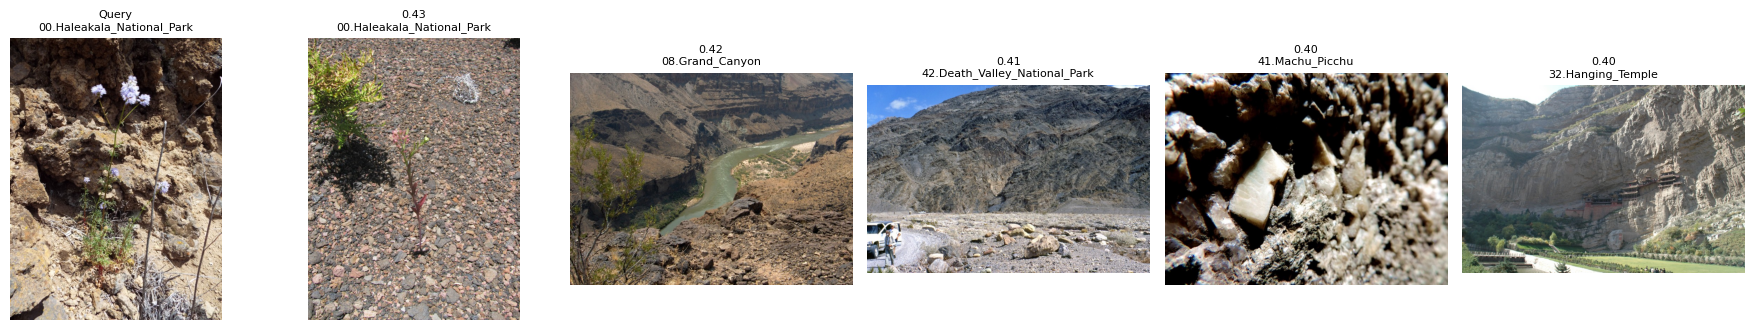

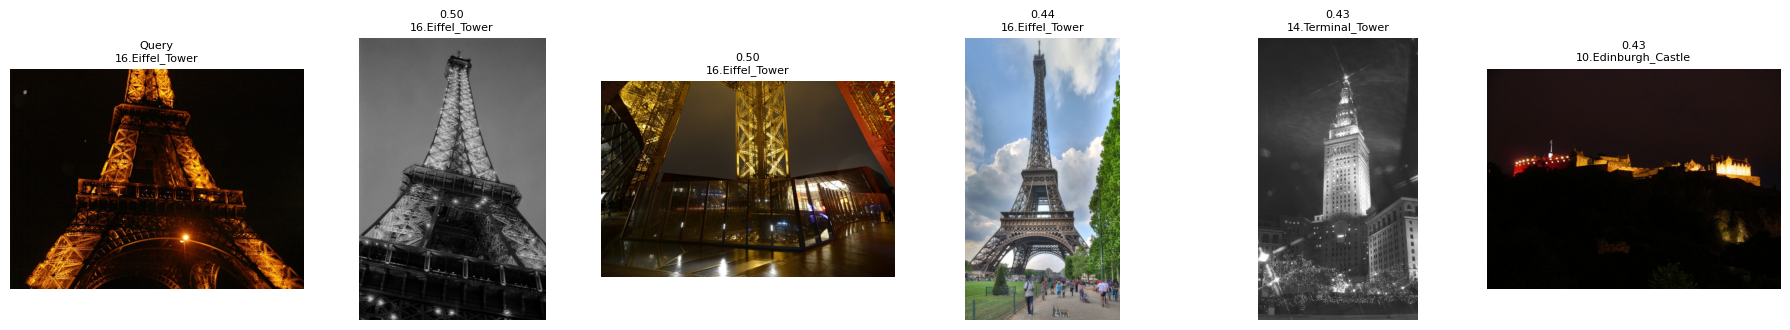

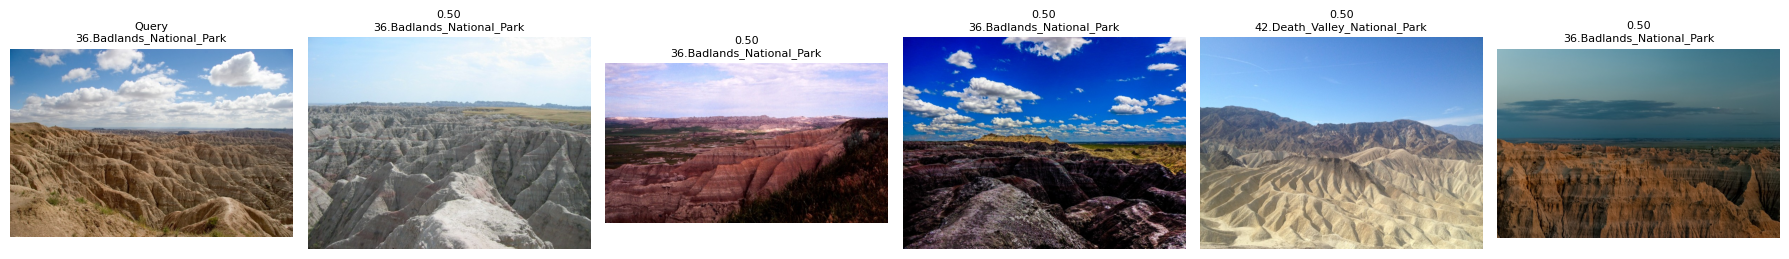

In [1]:
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms
from src.helpers import compute_mean_and_std, get_data_location
from src.transfer import get_model_transfer_learning

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

retrieval_checkpoint = Path("checkpoints/model_transfer.pt")
if not retrieval_checkpoint.is_file():
    raise FileNotFoundError(
        f"Missing {retrieval_checkpoint}. Train the final ResNet-50 model or copy its checkpoint here."
    )

mean, std = compute_mean_and_std()
gallery_dataset = datasets.ImageFolder(
    Path(get_data_location()) / "test",
    transform=transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean.tolist(), std.tolist()),
    ]),
)

# Load the final model, not whichever backbone was last used for an experiment.
feature_extractor = get_model_transfer_learning(
    "resnet50", n_classes=len(gallery_dataset.classes), pretrained=False
)
feature_extractor.load_state_dict(
    torch.load(retrieval_checkpoint, map_location="cpu", weights_only=True)
)
feature_extractor.fc = torch.nn.Identity()
feature_extractor = feature_extractor.to(device).eval()

gallery_loader = torch.utils.data.DataLoader(
    gallery_dataset, batch_size=64, shuffle=False, num_workers=0,
    pin_memory=device.type == "cuda",
)
gallery_paths = [path for path, _ in gallery_loader.dataset.samples]

with torch.inference_mode():
    gallery_features = torch.cat([
        torch.nn.functional.normalize(
            feature_extractor(images.to(device, non_blocking=True)), dim=1
        ).cpu()
        for images, _ in gallery_loader
    ])

# The gallery features are cached on the CPU; free the GPU copy of the network
del feature_extractor, gallery_loader
if torch.cuda.is_available():
    torch.cuda.empty_cache()


def retrieve(query_index, top_k=5):
    query = gallery_features[query_index]
    scores = gallery_features @ query
    scores[query_index] = float("-inf")  # do not return the query itself
    best = scores.topk(top_k)

    fig, axes = plt.subplots(1, top_k + 1, figsize=(3 * (top_k + 1), 3.4))
    paths = [gallery_paths[query_index]] + [gallery_paths[i] for i in best.indices]
    titles = ["Query"] + [f"{s:.2f}" for s in best.values]
    for ax, path, title in zip(axes, paths, titles):
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_title(f"{title}\n{path.split('/')[-2]}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


for query_index in (0, 400, 900):
    retrieve(query_index)

---
## (Stand out) Additional use cases

- **Photo organization and auto-tagging:** suggest location tags and albums for uploaded photos that lack GPS metadata.
- **Travel and tourism apps:** point a phone at a monument to get its name, history and opening hours, or recommend visually similar destinations through the retrieval features above.
- **Content moderation and de-duplication:** find near-duplicate or re-uploaded images by feature similarity.
- **Cultural-heritage archives:** index large historical photo collections by landmark to speed up archival search.
- **Geo-localization prior:** use the predicted landmark as a coarse location estimate for downstream mapping or AR applications.

Limitations: the model only knows 50 classes and will always pick one of them. A production system should add a confidence threshold or "unknown" handling and should be evaluated for bias toward popular, well-photographed viewpoints.